# 3 · Temporal-difference learning: from the cliff walk to a trading agent
**Part 1** reproduces the classic cliff-walking comparison of SARSA and Q-learning (Sutton & Barto, Example 6.6). It shows the difference between learning about the policy you follow (SARSA) and about the greedy policy (Q-learning).

**Part 2** builds a small, fully transparent Q-learning trader. Its state is the recent trend, recent volatility and current position; it decides each day whether to be long or in cash. It is trained on one period and judged on a later one it never saw, net of costs and over several random seeds, against buy-and-hold and a plain trend rule.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = ROOT / "images"; DATA = ROOT / "data"
from rlfin import tabular, trading

## Part 1 · Cliff walk

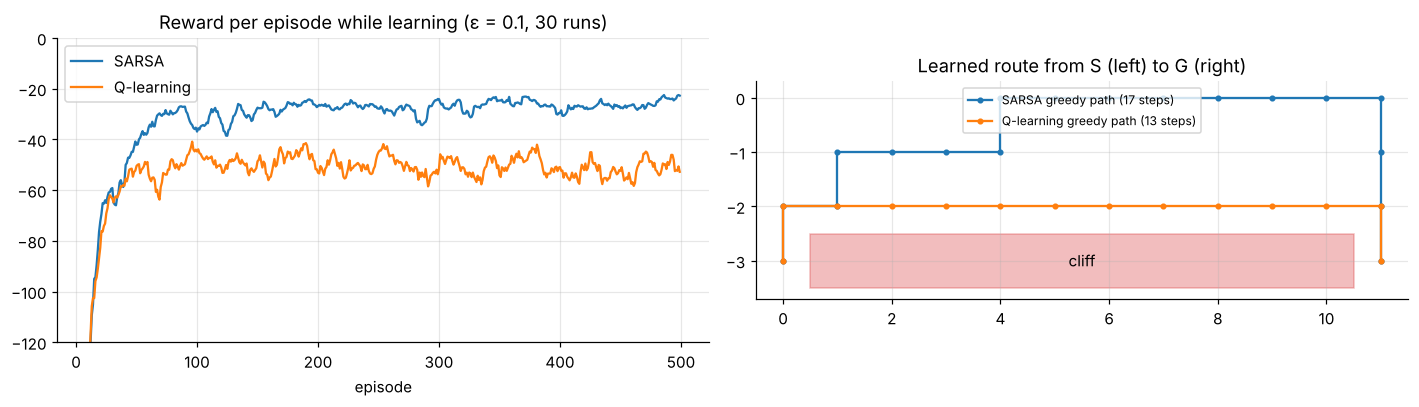

{'SARSA': np.float64(-26.2), 'Q-learning': np.float64(-52.1)} = average reward per episode over the last 100 episodes, while still exploring


In [2]:
env = tabular.CliffWalk()
curves, paths = {}, {}
for m, name in [("sarsa", "SARSA"), ("q", "Q-learning")]:
    runs = [tabular.td_control(env, m, episodes=500, alpha=0.5, eps=0.1, seed=s) for s in range(30)]
    curves[name] = np.mean([r for _, r in runs], axis=0)
    paths[name] = tabular.greedy_path(env, runs[0][0])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for n, c in curves.items(): ax[0].plot(pd.Series(c).rolling(10).mean(), label=n)
ax[0].set_ylim(-120, 0); ax[0].set_title("Reward per episode while learning (ε = 0.1, 30 runs)"); ax[0].set_xlabel("episode"); ax[0].legend()
ax[1].add_patch(plt.Rectangle((0.5, -3.5), 10, 1, color="C3", alpha=0.3)); ax[1].text(5.5, -3, "cliff", ha="center", va="center")
for n, p in paths.items():
    p = np.array(p); ax[1].plot(p[:, 1], -p[:, 0], "o-", ms=3, label=f"{n} greedy path ({len(p) - 1} steps)")
ax[1].set_xlim(-0.5, 11.5); ax[1].set_ylim(-3.7, 0.3); ax[1].set_aspect("equal"); ax[1].legend(fontsize=8, loc="upper center"); ax[1].set_title("Learned route from S (left) to G (right)")
plt.tight_layout(); plt.savefig(IMG / "cliff_walk.png", bbox_inches="tight"); plt.show()
print({n: round(c[-100:].mean(), 1) for n, c in curves.items()}, "= average reward per episode over the last 100 episodes, while still exploring")

## Part 2 · A Q-learning trader
* **State:** 20-day trend (3 buckets) × 20-day volatility (3 buckets) × current position (cash or long) = 18 states. Bucket edges are fitted on the training period only.
* **Actions:** be in cash or long for the next day. **Reward:** next-day log return of the position minus 5 bp per change of position.
* **Training:** Q-learning with 60 passes over the training history (γ = 0.95, ε = 0.1). The step size is 1/(visits to that state and action), so each Q-value becomes a running average. Daily returns are mostly noise, and a fixed step size makes the estimates chase it. Then the greedy policy is frozen and applied to the test period.

First, a single split for SPY: train 2005-2014, test 2015-Oct 2026.

In [3]:
px = pd.read_csv(DATA / "etfs_daily.csv", index_col=0, parse_dates=True)
COST, EPIS, SEEDS = 0.0005, 60, 10
def split_run(tk, train_end="2014-12-31", seeds=SEEDS):
    f = trading.features(px[tk]); tr, te = f[:train_end], f[pd.Timestamp(train_end) + pd.Timedelta(days=1):]
    s_tr, s_te = trading.bucketize(tr, tr), trading.bucketize(tr, te)
    agents = []
    for sd in range(seeds):
        Q = trading.train_q(s_tr, tr["next_ret"].to_numpy(), 9, episodes=EPIS, cost=COST, seed=sd)
        agents.append((Q, *trading.run_policy(Q, s_te, te["next_ret"].to_numpy(), COST)))
    trend_pos = (te["trend"] > 0).astype(int).to_numpy()
    trend = trend_pos * te["next_ret"].to_numpy() - COST * np.abs(np.diff(np.r_[0, trend_pos]))
    return te, agents, trend
te, agents, trend = split_run("SPY")
rows = {f"Q-agent seed {i}": {**trading.stats(r), "time long %": 100 * p.mean(), "trades/yr": np.abs(np.diff(p)).sum() / (len(p) / 252)} for i, (_, r, p) in enumerate(agents)}
rows["buy and hold"] = {**trading.stats(te["next_ret"].to_numpy()), "time long %": 100, "trades/yr": 0}
rows["trend rule: long if 20-day return > 0"] = {**trading.stats(trend), "time long %": 100 * (te["trend"] > 0).mean(), "trades/yr": np.nan}
tab = pd.DataFrame(rows).T
print(f"Test period {te.index[0]:%b %Y} to {te.index[-1]:%b %Y}, {len(te):,} days")
tab.round(2)

Test period Jan 2015 to Oct 2026, 2,974 days


,ann. return %,ann. vol %,Sharpe,max drawdown %,time long %,trades/yr
Q-agent seed 0,13.31,16.81,0.74,-33.72,76.09,11.27
Q-agent seed 1,13.51,17.53,0.72,-33.72,100.00,0.00
Q-agent seed 2,12.25,16.88,0.68,-33.72,94.05,25.08
Q-agent seed 3,13.51,17.53,0.72,-33.72,100.00,0.00
Q-agent seed 4,13.51,17.53,0.72,-33.72,100.00,0.00
Q-agent seed 5,13.51,17.53,0.72,-33.72,100.00,0.00
Q-agent seed 6,13.51,17.53,0.72,-33.72,100.00,0.00
Q-agent seed 7,12.11,17.08,0.67,-33.72,95.02,25.08
Q-agent seed 8,11.91,16.34,0.69,-33.72,71.12,36.35
Q-agent seed 9,13.51,17.53,0.72,-33.72,100.00,0.00


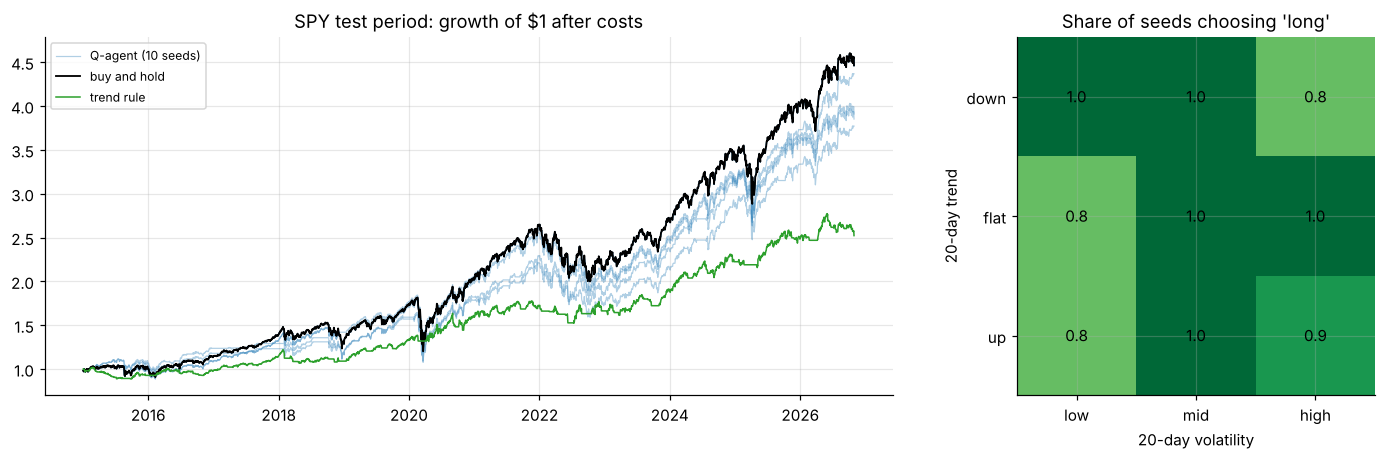

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
for i, (_, r, _) in enumerate(agents): ax[0].plot(te.index, np.exp(np.cumsum(r)), color="C0", alpha=0.35, lw=0.8, label="Q-agent (10 seeds)" if i == 0 else None)
ax[0].plot(te.index, np.exp(np.cumsum(te["next_ret"])), "k", lw=1.2, label="buy and hold")
ax[0].plot(te.index, np.exp(np.cumsum(trend)), "C2", lw=1, label="trend rule")
ax[0].set_title("SPY test period: growth of \\$1 after costs"); ax[0].legend(fontsize=8)
# learned policy, averaged across seeds: probability of choosing 'long' in each market state when currently flat
pol = np.mean([np.argmax(Q[:, 0], axis=1) for Q, _, _ in agents], axis=0).reshape(3, 3)
im = ax[1].imshow(pol, cmap="RdYlGn", vmin=0, vmax=1); ax[1].set_xticks(range(3), ["low", "mid", "high"]); ax[1].set_yticks(range(3), ["down", "flat", "up"])
ax[1].set_xlabel("20-day volatility"); ax[1].set_ylabel("20-day trend"); ax[1].set_title("Share of seeds choosing 'long'")
for (a, b), v in np.ndenumerate(pol): ax[1].text(b, a, f"{v:.1f}", ha="center", va="center")
plt.tight_layout(); plt.savefig(IMG / "q_trader_spy.png", bbox_inches="tight"); plt.show()

### Robustness: five markets, same design
The identical agent is trained on 2005-2014 and tested on 2015-2026 for US equities (SPY), Nasdaq-100 (QQQ), long Treasuries (TLT), gold (GLD) and emerging markets (EEM). The table shows the out-of-sample Sharpe ratio, with the median and range across 10 seeds.

In [5]:
rob = {}
for tk in ["SPY", "QQQ", "TLT", "GLD", "EEM"]:
    te_, ag, tr_ = split_run(tk)
    sh = np.array([trading.stats(r)["Sharpe"] for _, r, _ in ag])
    rob[tk] = {"buy-and-hold Sharpe": trading.stats(te_["next_ret"].to_numpy())["Sharpe"], "trend rule Sharpe": trading.stats(tr_)["Sharpe"],
               "Q-agent median Sharpe": np.median(sh), "Q-agent worst seed": sh.min(), "Q-agent best seed": sh.max(),
               "seeds beating buy-and-hold": int((sh > trading.stats(te_["next_ret"].to_numpy())["Sharpe"]).sum())}
rob = pd.DataFrame(rob).T
rob.round(2)

,buy-and-hold Sharpe,trend rule Sharpe,Q-agent median Sharpe,Q-agent worst seed,Q-agent best seed,seeds beating buy-and-hold
SPY,0.72,0.76,0.72,0.67,0.74,1.0
QQQ,0.77,0.90,0.81,0.53,1.01,5.0
TLT,-0.06,-0.08,-0.13,-0.36,-0.06,0.0
GLD,0.59,0.14,0.59,0.47,0.64,1.0
EEM,0.28,0.12,0.15,0.04,0.28,0.0


### Retraining every year (SPY)
A fairer protocol: each January, retrain on all data up to the previous December and trade the new year. 5 seeds per year.

In [6]:
f = trading.features(px["SPY"]); yr_rows = []; agent_r = []; bh_r = []
for y in range(2012, 2027):
    tr, te_y = f[: f"{y - 1}-12-31"], f[f"{y}-01-01": f"{y}-12-31"]
    if len(te_y) == 0: continue
    s_tr, s_te = trading.bucketize(tr, tr), trading.bucketize(tr, te_y)
    rs = [trading.run_policy(trading.train_q(s_tr, tr["next_ret"].to_numpy(), 9, episodes=EPIS, cost=COST, seed=sd), s_te, te_y["next_ret"].to_numpy(), COST)[0] for sd in range(5)]
    r = np.mean(rs, axis=0); agent_r.append(pd.Series(r, te_y.index)); bh_r.append(te_y["next_ret"])
    yr_rows.append({"year": y, "Q-agent %": 100 * (np.exp(r.sum()) - 1), "buy and hold %": 100 * (np.exp(te_y["next_ret"].sum()) - 1)})
yr = pd.DataFrame(yr_rows).set_index("year"); A, B = pd.concat(agent_r), pd.concat(bh_r)
print("2012-2026 (to Oct):", {k: {kk: round(vv, 2) for kk, vv in v.items()} for k, v in {"Q-agent (5-seed average)": trading.stats(A.to_numpy()), "buy and hold": trading.stats(B.to_numpy())}.items()})
print("years the agent beat buy-and-hold:", int((yr["Q-agent %"] > yr["buy and hold %"]).sum()), "of", len(yr))
yr.round(1).T

2012-2026 (to Oct): {'Q-agent (5-seed average)': {'ann. return %': np.float64(12.22), 'ann. vol %': np.float64(14.91), 'Sharpe': np.float64(0.77), 'max drawdown %': np.float64(-28.73)}, 'buy and hold': {'ann. return %': np.float64(14.74), 'ann. vol %': np.float64(16.51), 'Sharpe': np.float64(0.83), 'max drawdown %': np.float64(-33.72)}}
years the agent beat buy-and-hold: 1 of 15


year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Q-agent %,13.2,17.1,14.5,0.7,13.5,17.8,-5.8,26.8,15.6,25.6,-19.9,23.2,24.4,14.2,10.9
buy and hold %,17.1,27.8,14.5,-0.1,14.5,21.6,-5.1,32.3,15.6,31.3,-19.0,26.0,25.3,18.2,11.5


## Findings
* **Cliff walk:** Q-learning learns the shortest route along the cliff edge (13 steps), while SARSA learns a safer route further away (17 steps). Because of that, SARSA collects more reward while it is still exploring (-26 vs -52 per episode): Q-learning's occasional random step near the edge sends it over the cliff. The same distinction matters for trading: a strategy learned assuming perfect execution can be costly when execution is noisy.
* **The trading agent mostly learns to buy and hold.** Trained on SPY in 2005-2014 and tested in 2015-2026, 6 of 10 seeds end up permanently long and the rest are long 71-95% of the time. The out-of-sample Sharpe ratio ranges from 0.67 to 0.74 against 0.72 for buy-and-hold, so there is no improvement. The simple 20-day trend rule has a similar Sharpe (0.76) with lower return and much smaller drawdown (-14% vs -34%).
* **The same holds across markets.** The median out-of-sample Sharpe matches or trails buy-and-hold for SPY, TLT, GLD and EEM. Only QQQ shows a better median (0.81 vs 0.77), and the spread across seeds there (0.53 to 1.01) is wider than the gain.
* **Retraining every year does not change the picture.** Over 2012-2026 the 5-seed agent returns 12.2% a year (Sharpe 0.77) against 14.7% (0.83) for buy-and-hold and beats it in only one of 15 years. It gives up some upside in exchange for a slightly smaller drawdown (-29% vs -34%).
* **Why:** a daily return has a signal-to-noise ratio of about 0.05, so the value estimates of "long" and "cash" in any trend or volatility state are dominated by noise. The agent's main lesson is that equities drift up. A fixed step size made it worse: an earlier version that used a constant α = 0.05 chased noise and sat mostly in cash. A visit-count step size was needed just to reach buy-and-hold.